In [1]:
from pyprojroot import here
here = str(here())
import sys, os
sys.path.append(os.path.join(here,"utils"))

In [2]:
# basic pkgs
import os
import pandas as pd
import numpy as np
import glob

# analysis pkgs
import scanpy as sc
import anndata as ad
import decoupler as dc
 
# plotting pkgs
import matplotlib.pyplot as plt
from matplotlib import rcParams
import seaborn as sns

# own modules
from paths import *
from module import run_magic

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', -1)

%load_ext autoreload
%autoreload 2
%config IPCompleter.greedy=True

/scratch_tmp/53168586/ipykernel_120226/1173674903.py:23: FutureWarning: Passing a negative integer is deprecated in version 1.0 and will not be supported in future version. Instead, use None to not limit the column width.
  pd.set_option('display.max_colwidth', -1)


In [3]:
def config_rcparams():
    commonFontsize = 12
    plt.rcParams['font.family'] = ['sans-serif']
    plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
    plt.rcParams['font.size'] = commonFontsize
    plt.rcParams['axes.labelsize'] = commonFontsize
    plt.rcParams['xtick.labelsize'] = commonFontsize
    plt.rcParams['ytick.labelsize'] = commonFontsize
    plt.rcParams['axes.titlesize'] = 14
    # plt.rcParams['text'] = commonFontsize
    plt.rcParams['svg.fonttype'] = 'none'
    plt.rcParams['mathtext.fontset'] = 'custom'
    plt.rcParams['mathtext.cal'] = 'DejaVu Sans'
    plt.rcParams['mathtext.rm'] = 'DejaVu Sans'
    plt.rcParams['axes.edgecolor'] = 'black'
    plt.rcParams['ytick.color'] = 'black'
    plt.rcParams['axes.linewidth'] = 0.7
    plt.rcParams['xtick.major.width'] = 0.7
    plt.rcParams['ytick.major.width'] = 0.7
    plt.rcParams['xtick.major.size'] = 3
    plt.rcParams['ytick.major.size'] = 3
    


config_rcparams()  

In [4]:
path_to_figures = os.path.join(here, "AVGUSTINOVA_01_06_09_15", "4-annotation", version, "plots_"+version)
sc.settings.figdir = path_to_figures

In [5]:
df_info = pd.read_csv(os.path.join(here, "utils/info_samples.csv"))
df_info = df_info[(df_info["modality"] == "st") & (~df_info["quality"].isin(["Bad", "NM"]))] 

In [6]:
dict_samples = dict()

for sample in df_info['patient']:
    print(sample)
    
    batch = df_info[df_info['patient'] == sample].reset_index()["subproject"][0]
    exec(open(os.path.join(here, batch,"st_analysis/misc/paths.py")).read())
    path_to_data = os.path.join(here, batch, "st_analysis/3-clustering", version, "py_objects_"+version)
    
    # read object
    adata = sc.read_h5ad(os.path.join(path_to_data, sample+'.h5ad'))

   # add it to the dict
    dict_samples[sample] = adata

p11
p10
p5
p8
p4
p9
p7
p2
p6
p13
p14


## MSigDB gene sets

In [7]:
msigdb = dc.get_resource('MSigDB')
msigdb.head()

,genesymbol,collection,geneset
0,MAFF,chemical_and_genetic_perturbations,BOYAULT_LIVER_CANCER_SUBCLASS_G56_DN
1,MAFF,chemical_and_genetic_perturbations,ELVIDGE_HYPOXIA_UP
2,MAFF,chemical_and_genetic_perturbations,NUYTTEN_NIPP1_TARGETS_DN
3,MAFF,immunesigdb,GSE17721_POLYIC_VS_GARDIQUIMOD_4H_BMDC_DN
4,MAFF,chemical_and_genetic_perturbations,SCHAEFFER_PROSTATE_DEVELOPMENT_12HR_UP


In [8]:
msigdb["collection"].unique()

array(['chemical_and_genetic_perturbations', 'immunesigdb',
       'mirna_targets_mirdb', 'go_molecular_function', 'tf_targets_gtrf',
       'tf_targets_legacy', 'oncogenic_signatures',
       'cell_type_signatures', 'vaccine_response',
       'go_biological_process', 'cancer_gene_neighborhoods',
       'cancer_modules', 'go_cellular_component', 'wikipathways',
       'reactome_pathways', 'hallmark', 'mirna_targets_legacy',
       'biocarta_pathways', 'positional', 'human_phenotype_ontology',
       'pid_pathways', 'kegg_pathways'], dtype=object)

**HALLMARKS**

In [9]:
# Filter by hallmark
collec = msigdb[msigdb['collection']=='hallmark']

# Remove duplicated entries
collec = collec[~collec.duplicated(['geneset', 'genesymbol'])]

# Rename
collec.loc[:, 'geneset'] = [name.split('HALLMARK_')[1] for name in collec['geneset']]

collec.head()

,genesymbol,collection,geneset
233,MAFF,hallmark,IL2_STAT5_SIGNALING
250,MAFF,hallmark,COAGULATION
270,MAFF,hallmark,HYPOXIA
373,MAFF,hallmark,TNFA_SIGNALING_VIA_NFKB
377,MAFF,hallmark,COMPLEMENT


In [10]:
set(collec["geneset"].tolist())

{'ADIPOGENESIS',
 'ALLOGRAFT_REJECTION',
 'ANDROGEN_RESPONSE',
 'ANGIOGENESIS',
 'APICAL_JUNCTION',
 'APICAL_SURFACE',
 'APOPTOSIS',
 'BILE_ACID_METABOLISM',
 'CHOLESTEROL_HOMEOSTASIS',
 'COAGULATION',
 'COMPLEMENT',
 'DNA_REPAIR',
 'E2F_TARGETS',
 'EPITHELIAL_MESENCHYMAL_TRANSITION',
 'ESTROGEN_RESPONSE_EARLY',
 'ESTROGEN_RESPONSE_LATE',
 'FATTY_ACID_METABOLISM',
 'G2M_CHECKPOINT',
 'GLYCOLYSIS',
 'HEDGEHOG_SIGNALING',
 'HEME_METABOLISM',
 'HYPOXIA',
 'IL2_STAT5_SIGNALING',
 'IL6_JAK_STAT3_SIGNALING',
 'INFLAMMATORY_RESPONSE',
 'INTERFERON_ALPHA_RESPONSE',
 'INTERFERON_GAMMA_RESPONSE',
 'KRAS_SIGNALING_DN',
 'KRAS_SIGNALING_UP',
 'MITOTIC_SPINDLE',
 'MTORC1_SIGNALING',
 'MYC_TARGETS_V1',
 'MYC_TARGETS_V2',
 'MYOGENESIS',
 'NOTCH_SIGNALING',
 'OXIDATIVE_PHOSPHORYLATION',
 'P53_PATHWAY',
 'PANCREAS_BETA_CELLS',
 'PEROXISOME',
 'PI3K_AKT_MTOR_SIGNALING',
 'PROTEIN_SECRETION',
 'REACTIVE_OXYGEN_SPECIES_PATHWAY',
 'SPERMATOGENESIS',
 'TGF_BETA_SIGNALING',
 'TNFA_SIGNALING_VIA_NFKB',
 'UNFO

In [11]:
for sample, adata in dict_samples.items():
    dc.run_mlm(mat=adata, net=collec, source='geneset', target='genesymbol', weight=None, verbose=True)

    # Store them in a different key
    adata.obsm['msigdb_mlm_estimate'] = adata.obsm['mlm_estimate'].copy()
    adata.obsm['msigdb_mlm_pvals'] = adata.obsm['mlm_pvals'].copy()

Running mlm on mat with 3198 samples and 22411 targets for 50 sources.


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:01<00:00,  1.11s/it]


Running mlm on mat with 1728 samples and 22811 targets for 50 sources.


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.33it/s]


Running mlm on mat with 3871 samples and 22249 targets for 50 sources.


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:01<00:00,  1.34s/it]


Running mlm on mat with 2584 samples and 23332 targets for 50 sources.


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:01<00:00,  1.03s/it]


Running mlm on mat with 1097 samples and 19648 targets for 50 sources.


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  2.29it/s]


17 features of mat are empty, they will be removed.
Running mlm on mat with 1925 samples and 18334 targets for 50 sources.


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.38it/s]


6 features of mat are empty, they will be removed.
Running mlm on mat with 1296 samples and 19406 targets for 50 sources.


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.90it/s]


163 features of mat are empty, they will be removed.
Running mlm on mat with 1697 samples and 20645 targets for 50 sources.


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.40it/s]


39 features of mat are empty, they will be removed.
Running mlm on mat with 1205 samples and 19170 targets for 50 sources.


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  2.32it/s]


Running mlm on mat with 1581 samples and 21213 targets for 50 sources.


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.65it/s]


Running mlm on mat with 1352 samples and 21374 targets for 50 sources.


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.83it/s]


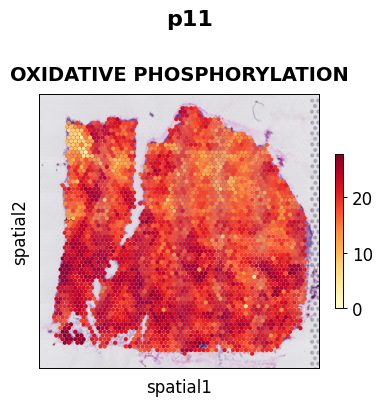

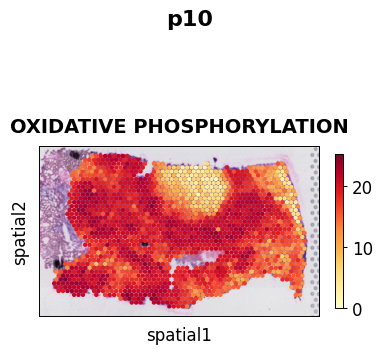

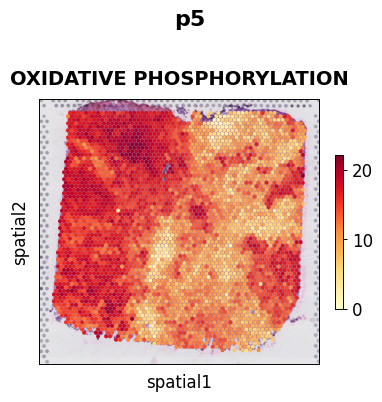

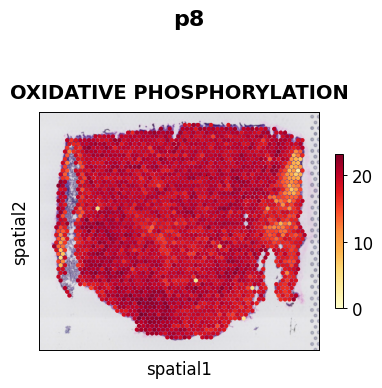

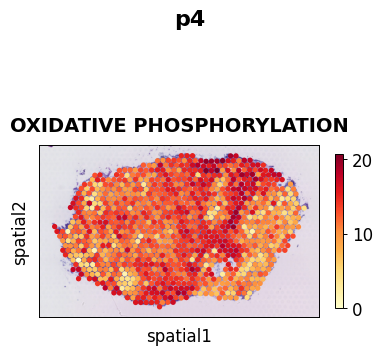

...

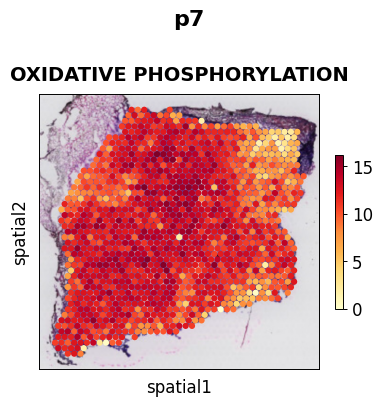

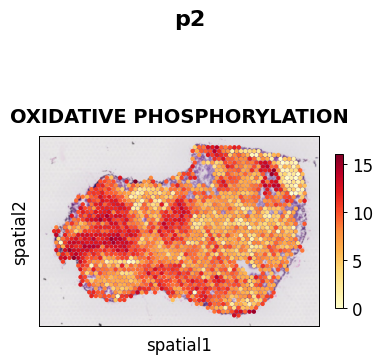

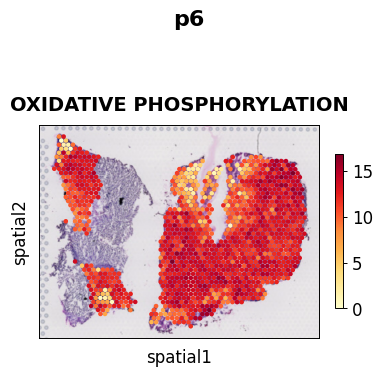

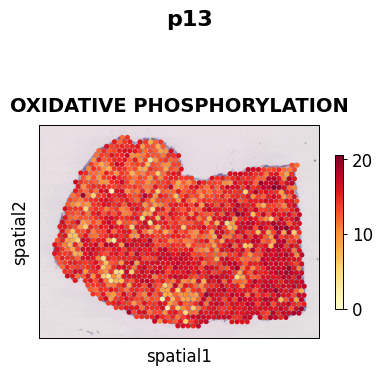

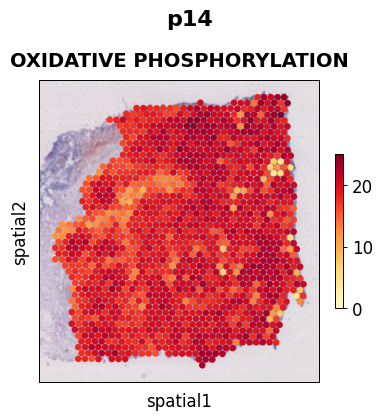

In [12]:
plt.rcParams["figure.figsize"] = (4,4)
for sample, adata in dict_samples.items():
    acts = dc.get_acts(adata, obsm_key='msigdb_mlm_estimate')
    axes = sc.pl.spatial(
        acts, 
        color=["OXIDATIVE_PHOSPHORYLATION"], 
        vmin=0,
        cmap='YlOrRd', 
        size=1.5, 
        show=False,
        colorbar_loc=None
    )
    ax = axes[0]
    mappable = ax.collections[0]
    
    cbar = plt.colorbar(
        mappable,
        ax=ax,
        shrink=0.5,   
        aspect=20,
        pad=0.05,
        fraction=0.046 
    )
    
    # 4. Customize fonts as before
    cbar.ax.tick_params(labelsize=12)
    
    ax.set_title("OXIDATIVE PHOSPHORYLATION", fontsize=14, fontweight='bold', pad=10)

    # Suptitle for the Sample
    plt.suptitle(sample, fontsize=16, ha="center", va="top", fontweight='bold', y=1.05)
    
    plt.savefig(
        os.path.join(path_to_figures, f"4.3.1-OXPHOS_{sample}.svg"), 
        format='svg', 
        bbox_inches='tight', 
        dpi=300
    )
    plt.show()

## Cell-Cell Communication genes

p11
Calculating MAGIC...
  Running MAGIC on 3198 cells and 22411 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 3.89 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.28 seconds.
    Calculating affinities...
    Calculated affinities in 0.29 seconds.
  Calculated graph and diffusion operator in 4.50 seconds.
  Calculating imputation...
Calculated MAGIC in 4.70 seconds.


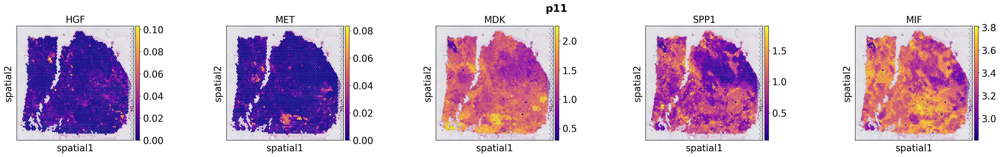

p10
Calculating MAGIC...
  Running MAGIC on 1728 cells and 22811 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 2.73 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.08 seconds.
    Calculating affinities...
    Calculated affinities in 0.08 seconds.
  Calculated graph and diffusion operator in 2.93 seconds.
  Calculating imputation...
Calculated MAGIC in 3.10 seconds.


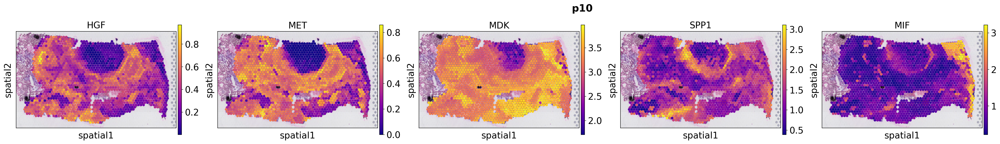

p5
Calculating MAGIC...
  Running MAGIC on 3871 cells and 22249 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 4.55 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.37 seconds.
    Calculating affinities...
    Calculated affinities in 0.38 seconds.
  Calculated graph and diffusion operator in 5.37 seconds.
  Calculating imputation...
Calculated MAGIC in 5.59 seconds.


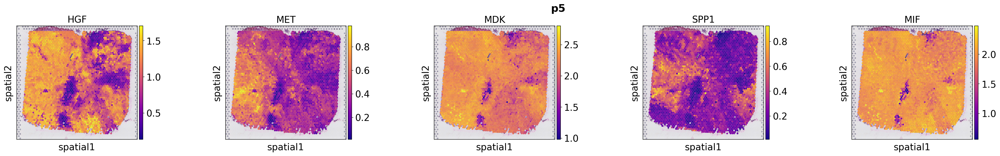

p8
Calculating MAGIC...
  Running MAGIC on 2584 cells and 23332 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 3.60 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.21 seconds.
    Calculating affinities...
    Calculated affinities in 0.21 seconds.
  Calculated graph and diffusion operator in 4.08 seconds.
  Calculating imputation...
Calculated MAGIC in 4.27 seconds.


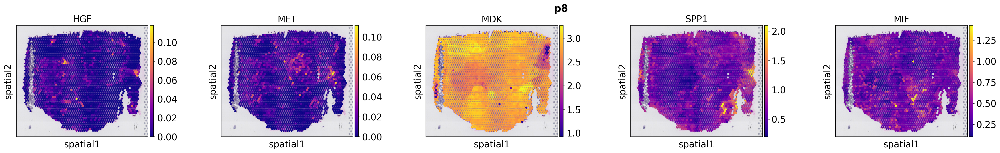

p4
Calculating MAGIC...
  Running MAGIC on 1097 cells and 19648 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 1.98 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.04 seconds.
    Calculating affinities...
    Calculated affinities in 0.04 seconds.
  Calculated graph and diffusion operator in 2.09 seconds.
  Calculating imputation...
Calculated MAGIC in 2.22 seconds.


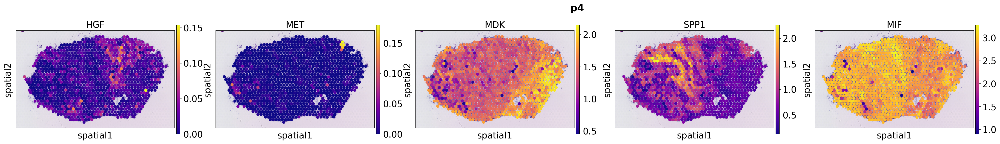

p9
Calculating MAGIC...
  Running MAGIC on 1925 cells and 18351 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...


/home/groups/singlecell/isentis/.local/lib/python3.8/site-packages/magic/magic.py:425: UserWarning: Input matrix contains unexpressed genes. Please remove them prior to running MAGIC.
  warnings.warn(


    Calculated PCA in 2.97 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.11 seconds.
    Calculating affinities...
    Calculated affinities in 0.12 seconds.
  Calculated graph and diffusion operator in 3.24 seconds.
  Calculating imputation...
Calculated MAGIC in 3.38 seconds.


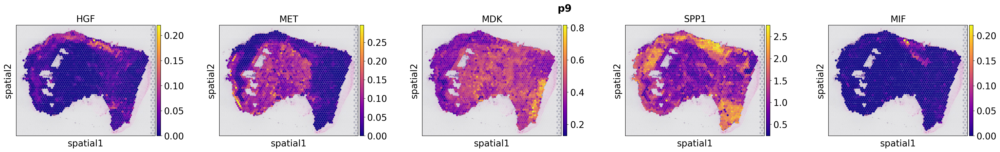

p7
Calculating MAGIC...
  Running MAGIC on 1296 cells and 19412 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...


/home/groups/singlecell/isentis/.local/lib/python3.8/site-packages/magic/magic.py:425: UserWarning: Input matrix contains unexpressed genes. Please remove them prior to running MAGIC.
  warnings.warn(


    Calculated PCA in 2.44 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.05 seconds.
    Calculating affinities...
    Calculated affinities in 0.05 seconds.
  Calculated graph and diffusion operator in 2.57 seconds.
  Calculating imputation...
Calculated MAGIC in 2.70 seconds.


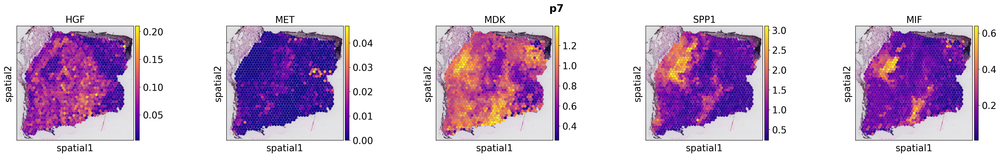

p2
Calculating MAGIC...
  Running MAGIC on 1697 cells and 20808 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...


/home/groups/singlecell/isentis/.local/lib/python3.8/site-packages/magic/magic.py:425: UserWarning: Input matrix contains unexpressed genes. Please remove them prior to running MAGIC.
  warnings.warn(


    Calculated PCA in 2.72 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.08 seconds.
    Calculating affinities...
    Calculated affinities in 0.09 seconds.
  Calculated graph and diffusion operator in 2.93 seconds.
  Calculating imputation...
Calculated MAGIC in 3.08 seconds.


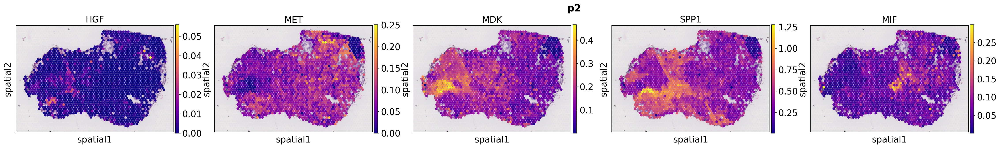

p6
Calculating MAGIC...
  Running MAGIC on 1205 cells and 19209 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...


/home/groups/singlecell/isentis/.local/lib/python3.8/site-packages/magic/magic.py:425: UserWarning: Input matrix contains unexpressed genes. Please remove them prior to running MAGIC.
  warnings.warn(


    Calculated PCA in 2.13 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.04 seconds.
    Calculating affinities...
    Calculated affinities in 0.04 seconds.
  Calculated graph and diffusion operator in 2.24 seconds.
  Calculating imputation...
Calculated MAGIC in 2.36 seconds.


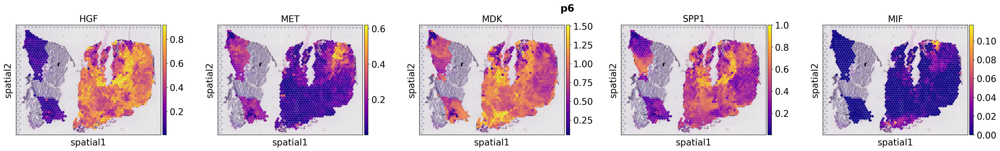

p13
Calculating MAGIC...
  Running MAGIC on 1581 cells and 21213 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 2.86 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.07 seconds.
    Calculating affinities...
    Calculated affinities in 0.08 seconds.
  Calculated graph and diffusion operator in 3.05 seconds.
  Calculating imputation...
Calculated MAGIC in 3.20 seconds.


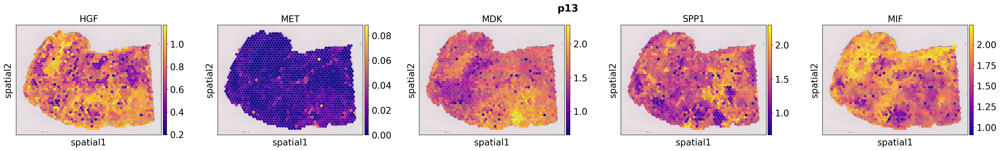

p14
Calculating MAGIC...
  Running MAGIC on 1352 cells and 21374 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 2.53 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.05 seconds.
    Calculating affinities...
    Calculated affinities in 0.06 seconds.
  Calculated graph and diffusion operator in 2.67 seconds.
  Calculating imputation...
Calculated MAGIC in 2.81 seconds.


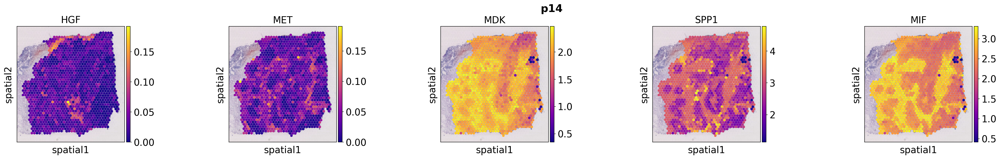

In [13]:
sc.set_figure_params(fontsize=18)
plt.rcParams["figure.figsize"] = (6,4)
for sample, an in dict_samples.items():
    base_markers = ["HGF","MET","MDK","SPP1","MIF"]
    print(sample)
    an.obs = an.obs[an.obs.columns.drop(an.obs.filter(regex='_MAGIC'))]
    an = run_magic(an, base_markers)
    plot_markers = [m+"_MAGIC" for m in base_markers]
    sc.pl.spatial(an, color=plot_markers, 
                      cmap='plasma', size=1.5, title = base_markers,
                      show=False, ncols=5)

    an.obs = an.obs[an.obs.columns.drop(an.obs.filter(regex='_MAGIC'))]

    fig = plt.gcf()
    
    fig.suptitle(r"$\mathbf{" + sample + "}$", fontsize=20, y=1.05, x=0.5) 
    plt.savefig(
        os.path.join(path_to_figures, f"4.3.1-LR_genes_{sample}.svg"), 
        format='svg', 
        bbox_inches='tight', 
        dpi=300
    )
    plt.show()